# CI failure prediction on GitHub Actions - CART decision tree

Trains and evaluates the from-scratch CART tree (`tree/cart.py`, Breiman et al., 1984) on the **pooled** dataset (the enabled targets of `config/targets.json`, analysed as one CI workflow), with the frozen feature lists from `feature_selection.ipynb`.

**Protocol.** The dev segment (first 20% of the pooled runs) is followed by 5 expanding-window folds. Each train set is dev + the window so far; its last 20% is the **validation** tail. The hyperparameters, the pruning alpha and the decision threshold are chosen on validation only (`tree/tune.py`); each test fold is read once, after the tree is final.

**Per source.** Each fold's test rows are also scored per source: `run_cv` adds one row per fold and source next to the pooled row (`source = "all"`). The model is the same; only the scored rows differ.

**Targets.** T2 (runs whose previous run in the same lineage passed, or that open a lineage) is the main target; T1 (all runs) is secondary, for the comparison with Parrot.

**Baselines.** Parrot (previous outcome of the same lineage; on T2 always "pass"), majority class, and sklearn's `DecisionTreeClassifier` with the same choices per fold (a reference for the implementation, not a competitor).

**Random forest.** Section 9 repeats the CV with a forest of 100 bagged CART trees (`tree/forest.py`, Breiman, 2001): a stronger but not explainable comparison point.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import Markdown, display
from sklearn.metrics import matthews_corrcoef
from sklearn.tree import DecisionTreeClassifier
from acise_p2_cidt.analysis.features import load_features
from acise_p2_cidt.collect.targets import load_targets, slug
from acise_p2_cidt.data.load import load, pool_name
from acise_p2_cidt.metrics.metrics import majority, parrot
from acise_p2_cidt.stats import tests as st
from acise_p2_cidt.training.cv import dev_split, folds, prepare, run_cv
from acise_p2_cidt.tree import forest, tune
from acise_p2_cidt.tree.cart import CART
from acise_p2_cidt.viz import plots

SOURCES = [slug(c.target) for c in load_targets()]
DATASET = pool_name(SOURCES)
TARGETS = ("T2", "T1")
METRICS = ["mcc", "f1", "precision", "recall", "accuracy", "pct_builds_saved", "pct_failures_caught"]
data = {t: load(SOURCES, t) for t in TARGETS}
feats = {t: load_features(t, DATASET) for t in TARGETS}
fold_lists = {t: folds(data[t]) for t in TARGETS}
splits = {t: [prepare(data[t], feats[t], f) for f in fold_lists[t]] for t in TARGETS}
display(
    Markdown(f"**Pooled dataset `{DATASET}`** ({len(SOURCES)} sources): rows, failures, dev rows and frozen features per target"),
    pd.DataFrame(
        {
            t: {
                "rows": ds.meta["n_rows"],
                "failed": ds.meta["n_failed"],
                "fail_%": round(100 * ds.y.mean(), 2),
                "dev_rows": ds.meta["n_dev"],
                "features": len(feats[t]),
            }
            for t, ds in data.items()
        }
    ),
)

**Pooled dataset `pool-67fa17e1`** (13 sources): rows, failures, dev rows and frozen features per target

,T2,T1
rows,20488.00,25114.00
failed,3127.00,5472.00
fail_%,15.26,21.79
dev_rows,4097.00,5022.00
features,19.00,20.00


## 1. CART walkthrough (T2, dev split)

One tree on the dev split (head of dev = fit rows, tail = validation), depth 3, `class_weight="balanced"`. Each internal node is a test `x <= t` in raw units (no scaling, see the plan); each leaf gives P(fail) as the weighted share of failed runs that reach it.

In [2]:
dev = dev_split(data["T2"], feats["T2"])
demo = CART(max_depth=3, min_samples_leaf=10, class_weight="balanced").fit(dev.X_fit, dev.y_fit)
print(f"depth {demo.depth_}, leaves {demo.n_leaves_}\n")
print(demo.export_text())

depth 3, leaves 8

|--- fail_rate_7d <= 0.142136
|   |--- author_prior_fail_rate <= 0.0801282
|   |   |--- days_since_workflow_change <= 11.1381
|   |   |   |--- leaf: P(fail) = 0.32 from 169 runs
|   |   |--- days_since_workflow_change > 11.1381
|   |   |   |--- leaf: P(fail) = 0.04 from 629 runs
|   |--- author_prior_fail_rate > 0.0801282
|   |   |--- days_since_workflow_change <= 89.4244
|   |   |   |--- leaf: P(fail) = 0.36 from 161 runs
|   |   |--- days_since_workflow_change > 89.4244
|   |   |   |--- leaf: P(fail) = 0.82 from 27 runs
|--- fail_rate_7d > 0.142136
|   |--- file_fail_prob_max <= 0.496575
|   |   |--- fail_rate_1h <= 0.105296
|   |   |   |--- leaf: P(fail) = 0.35 from 355 runs
|   |   |--- fail_rate_1h > 0.105296
|   |   |   |--- leaf: P(fail) = 0.55 from 1108 runs
|   |--- file_fail_prob_max > 0.496575
|   |   |--- fail_rate_7d <= 0.490897
|   |   |   |--- leaf: P(fail) = 0.69 from 763 runs
|   |   |--- fail_rate_7d > 0.490897
|   |   |   |--- leaf: P(fail) = 0.26 

`explain` gives the path of one run: the tests it passed, then the leaf. Shown for the first failed run of the validation tail.

fail_rate_7d = 0.295082 > 0.142136
file_fail_prob_max = 1 > 0.496575
fail_rate_7d = 0.295082 <= 0.490897
leaf: P(fail) = 0.69 from 763 runs
actual: fail


[11/08/2026 04:25:20 PM] INFO     Saved figure: /home/culbec/uni/ACISE/projects/2/results/figures/tree_demo_T2.*

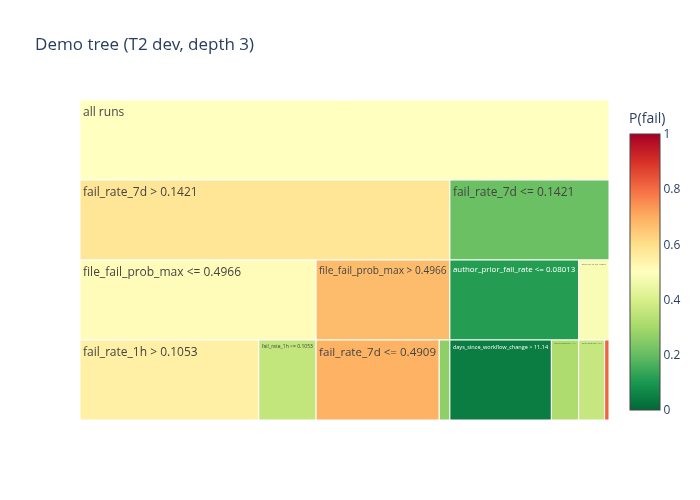

In [3]:
i = int(np.flatnonzero(dev.y_val.to_numpy())[0])
print("\n".join(demo.explain(dev.X_val.iloc[i])))
print("actual: fail")
plots.save(
    plots.tree_icicle(demo.tree_, demo.feature_names_, max_depth=3).update_layout(title="Demo tree (T2 dev, depth 3)"),
    "tree_demo_T2",
)

**Reference check.** sklearn's tree with the same parameters. When two splits have exactly the same gain, sklearn takes one at random (it shuffles the features), CART takes the first column, so the two trees can differ on ties only. `tests/test_cart.py` checks that every difference is such a tie. sklearn fits on float32, so its input is cast here.

In [4]:
X32 = dev.X_fit.astype("float32")
sk = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=0).fit(X32, dev.y_fit)
agree = np.mean(demo.predict(dev.X_fit) == sk.predict(X32).astype(bool))
print(f"root impurity: CART {demo.tree_.impurity[0]:.6f}, sklearn {sk.tree_.impurity[0]:.6f}")
print(f"leaves: CART {demo.n_leaves_}, sklearn {sk.get_n_leaves()}; training predictions agree on {agree:.1%}")

root impurity: CART 0.500000, sklearn 0.500000
leaves: CART 8, sklearn 8; training predictions agree on 100.0%


## 2. Overfitting control (T2)

**Depth.** In each CV fold, an unpruned tree per depth (`min_samples_leaf=10`, Gini, balanced), scored at threshold 0.5 on the fit rows and on the validation tail. A train line that keeps rising while the validation line stays flat is overfitting.

[11/08/2026 04:26:03 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_valcurve_depth_T2.*

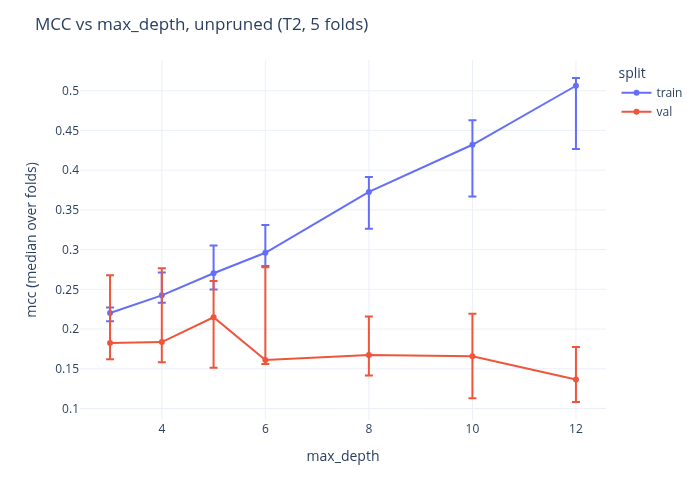

In [5]:
BASE = {"min_samples_leaf": 10, "criterion": "gini", "class_weight": "balanced"}
rows = []
for k, s in enumerate(splits["T2"]):
    for d in [*tune.GRID["max_depth"], 10, 12]:
        m = CART(max_depth=d, **BASE).fit(s.X_fit, s.y_fit)
        for name, X, y in (("train", s.X_fit, s.y_fit), ("val", s.X_val, s.y_val)):
            rows.append({"fold": k, "max_depth": d, "split": name, "mcc": matthews_corrcoef(y, m.predict(X))})
plots.save(
    plots.validation_curve(pd.DataFrame(rows), "max_depth").update_layout(title="MCC vs max_depth, unpruned (T2, 5 folds)"),
    "tree_valcurve_depth_T2",
)

**Pruning.** A depth-8 tree on the dev split, scored at every alpha of its cost-complexity path. `tune.choose_alpha` takes the alpha with the best validation MCC (ties: the larger alpha, the smaller tree).

chosen alpha: 0.00239124023384904


[11/08/2026 04:26:35 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_valcurve_alpha_T2.*

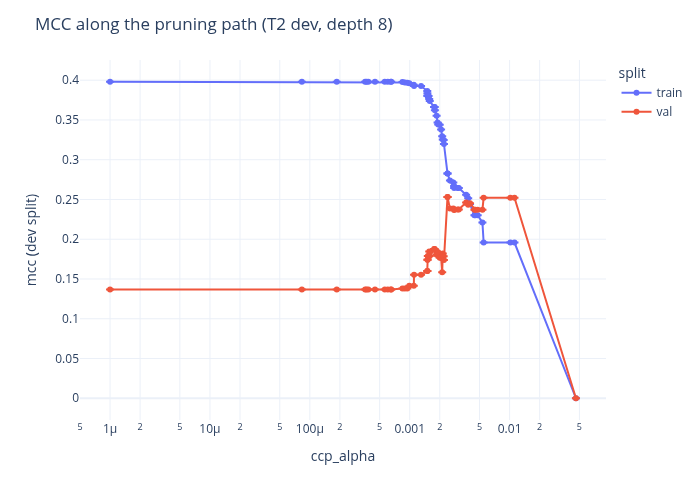

In [6]:
deep = CART(max_depth=8, **BASE).fit(dev.X_fit, dev.y_fit)
rows = []
for a in np.unique(deep.cost_complexity_path()[0]):
    p = deep.pruned(a)
    for name, X, y in (("train", dev.X_fit, dev.y_fit), ("val", dev.X_val, dev.y_val)):
        # alpha 0 (the unpruned tree) is drawn at 1e-6, so it fits on the log axis
        rows.append({"ccp_alpha": max(a, 1e-6), "split": name, "mcc": matthews_corrcoef(y, p.predict(X)), "leaves": p.n_leaves_})
alpha_df = pd.DataFrame(rows)
print("chosen alpha:", tune.choose_alpha(deep, dev))
plots.save(
    plots.validation_curve(alpha_df, "ccp_alpha", log_x=True)
    .update_layout(title="MCC along the pruning path (T2 dev, depth 8)")
    .update_yaxes(title_text="mcc (dev split)"),
    "tree_valcurve_alpha_T2",
)

## 3. Tuning on the dev split

The full grid (`max_depth` x `min_samples_leaf` x criterion x class weight = 60 points) on the dev split, as in project 1. For each point: fit, prune on validation, tune the threshold on validation. The CV below repeats this inside every fold, so this table only shows how flat the grid is.

In [7]:
best_dev, grid_dev = tune.grid_search(dev)
print(best_dev)
display(
    Markdown("**Grid search on the dev split** (T2): the 10 best grid points by validation MCC"),
    grid_dev.sort_values("val_mcc", ascending=False).head(10).round(4),
)

Choice(params={'max_depth': 6, 'min_samples_leaf': 20, 'criterion': 'gini', 'class_weight': 'balanced'}, alpha=0.0013452030992959288, threshold=0.08311874962572606, val_mcc=0.28309882451847757)


**Grid search on the dev split** (T2): the 10 best grid points by validation MCC

,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,val_mcc,depth,n_leaves
45,6,20,gini,balanced,0.0013,0.0831,0.2831,6,28
38,6,5,entropy,NaN,0.0019,0.0700,0.2793,6,22
46,6,20,entropy,NaN,0.0009,0.0809,0.2780,6,40
25,5,5,gini,balanced,0.0021,0.0831,0.2778,5,19
29,5,10,gini,balanced,0.0021,0.0831,0.2778,5,19
41,6,10,gini,balanced,0.0021,0.0831,0.2778,6,22
33,5,20,gini,balanced,0.0021,0.0831,0.2778,5,18
53,8,10,gini,balanced,0.0024,0.0831,0.2736,7,19
49,8,5,gini,balanced,0.0024,0.0831,0.2736,7,19
57,8,20,gini,balanced,0.0024,0.0831,0.2736,7,18


## 4. Cross-validation

Each fold: grid search on the validation tail, then one prediction of the test fold. `sklearn` uses CART's choice of each fold (params, alpha, threshold); it shows how much the from-scratch implementation itself changes the result.

In [9]:
def sklearn_ref(choices: list[tune.Choice]):
    """sklearn tree with CART's choice per fold; run_cv visits the folds in order."""
    it = iter(choices)

    def fit_predict(split):
        c = next(it)
        m = DecisionTreeClassifier(**c.params, ccp_alpha=c.alpha, random_state=0).fit(split.X_fit, split.y_fit)
        return m.predict_proba(split.X_test)[:, 1] > c.threshold

    return fit_predict


results, payloads = {}, {}
for t in TARGETS:
    print(f"Target: {t}")
    ds, f = data[t], feats[t]
    cart, payloads[t] = run_cv(ds, f, tune.fit_predict, "cart")
    choices = [payloads[t][k]["choice"] for k in sorted(payloads[t])]
    results[t] = pd.concat(
        [
            cart,
            run_cv(ds, f, sklearn_ref(choices), "sklearn")[0],
            run_cv(ds, f, parrot, "parrot")[0],
            run_cv(ds, f, majority, "majority")[0],
        ],
        ignore_index=True,
    )

Output()

[11/08/2026 04:27:01 PM] INFO     cart fold 1/5: fit 5467, val 1366, test 2731 (471 failures)

Target: T2


[11/08/2026 04:27:05 PM] INFO     cart fold 2/5: fit 7652, val 1912, test 2731 (421 failures)

[11/08/2026 04:27:11 PM] INFO     cart fold 3/5: fit 9836, val 2459, test 2731 (434 failures)

/home/culbec/uni/ACISE/projects/2/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:614: 
UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape,
use the 'labels' parameter to pass all known labels.
  warnings.warn(

... (51 outputs left out)

                         INFO     majority fold 3/5: fit 12056, val 3014, test 3348 (784 failures)

/home/culbec/uni/ACISE/projects/2/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:614: 
UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape,
use the 'labels' parameter to pass all known labels.
  warnings.warn(

                         INFO     majority fold 4/5: fit 14735, val 3683, test 3348 (679 failures)

                         INFO     majority fold 5/5: fit 17413, val 4353, test 3348 (675 failures)

Choice per fold, with the validation MCC it was chosen on next to the test MCC.

In [10]:
test_mcc = {t: results[t].query("method == 'cart' and source == 'all'").set_index("fold")["mcc"] for t in TARGETS}
display(
    Markdown("**CART choice per fold**: grid parameters, pruning alpha, threshold, tree size, the validation MCC it "
             "was chosen on, and the pooled test MCC"),
    pd.DataFrame(
        [
            {
                "target": t,
                "fold": k,
                **p["choice"].params,
                "alpha": p["choice"].alpha,
                "threshold": p["choice"].threshold,
                "depth": p["tree"].depth_,
                "leaves": p["tree"].n_leaves_,
                "val_mcc": p["choice"].val_mcc,
                "test_mcc": test_mcc[t][k],
            }
            for t in TARGETS
            for k, p in payloads[t].items()
        ]
    ).round(4),
)

**CART choice per fold**: grid parameters, pruning alpha, threshold, tree size, the validation MCC it was chosen on, and the pooled test MCC

,target,fold,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,depth,leaves,val_mcc,test_mcc
0,T2,0,4,5,gini,balanced,0.0023,0.6239,4,12,0.3282,0.1837
1,T2,1,5,5,gini,balanced,0.0009,0.5000,5,22,0.2449,0.1878
2,T2,2,8,5,gini,NaN,0.0007,0.2727,8,21,0.2664,0.1132
3,T2,3,5,5,gini,balanced,0.0011,0.5000,5,19,0.2384,0.2098
4,T2,4,8,5,entropy,balanced,0.0016,0.6858,8,42,0.2110,0.1779
5,T1,0,4,5,gini,balanced,0.0009,0.7546,4,12,0.4593,0.3059
6,T1,1,6,5,gini,NaN,0.0004,0.3750,6,31,0.3030,0.3571
7,T1,2,4,5,entropy,balanced,0.0032,0.6661,4,9,0.3951,0.3539
8,T1,3,8,10,gini,NaN,0.0003,0.5294,8,63,0.3965,0.2560
9,T1,4,8,5,entropy,NaN,0.0012,0.5000,8,22,0.3564,0.3777


Mean +/- std over the 5 test folds (sample std, ddof=1), first on the pooled test rows, then per source on each source's own test rows. A source with few failures in a fold gives a noisy score: the last table counts the failures per fold and source. In the box plots (pooled) the dashed line is the mean and the diamond spans mean +/- 1 std. The line chart shows each fold separately: a fold that is hard for every method is a property of that period, not of the model.

**CV results, pooled** (T2, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.174 +/- 0.036,0.319 +/- 0.038,0.257 +/- 0.029,0.474 +/- 0.193,0.698 +/- 0.089,70.604 +/- 14.548,47.413 +/- 19.342
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.846 +/- 0.014,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.846 +/- 0.014,100.000 +/- 0.000,0.000 +/- 0.000
sklearn,0.172 +/- 0.032,0.318 +/- 0.035,0.256 +/- 0.030,0.470 +/- 0.188,0.698 +/- 0.089,70.707 +/- 14.439,47.022 +/- 18.812


**CV results per source** (T2, mean +/- std over the 5 test folds)

mcc  \
source                             method                       
Homebrew__brew__9591               cart       0.136 +/- 0.190   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.136 +/- 0.190   
astral-sh__ruff__32130301          cart       0.205 +/- 0.116   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.205 +/- 0.116   
astral-sh__uv__82881044            cart       0.058 +/- 0.087   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.049 +/- 0.076   
github__gh-aw__180858647           cart       0.060 +/- 0.184   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.060 +/- 0.184   
n8n-io__n8n__33322401              cart       0.143 +/- 0.038   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.141 +/- 0.042   
n8n-io__n8n__33323319@master       cart       0.047 +/- 0.091   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.047 +/- 0.091   
nushell__nushell__7519865          cart      -0.017 +/- 0.025   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn   -0.017 +/- 0.025   
servo__servo__3876879              cart       0.156 +/- 0.047   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.157 +/- 0.047   
sharkdp__fd__11202521              cart       0.012 +/- 0.243   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.012 +/- 0.243   
sveltejs__svelte__14783            cart       0.166 +/- 0.314   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.114 +/- 0.340   
tokio-rs__tokio__1972898           cart       0.114 +/- 0.268   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.114 +/- 0.268   
windmill-labs__windmill__133951533 cart       0.351 +/- 0.240   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.351 +/- 0.240   
windmill-labs__windmill__45664283  cart       0.104 +/- 0.165   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
                                   sklearn    0.104 +/- 0.165   

                                                      recall        precision  
source                             method                                      
Homebrew__brew__9591               cart      0.138 +/- 0.179  0.213 +/- 0.229  
                                   majority  0.000 +/- 0.000  0.000 +/- 0.000  
                                   parrot    0.000 +/- 0.000  0.000 +/- 0.000  
                                   sklearn   0.138 +/- 0.179  0.213 +/- 0.229  
astral-sh__ruff__32130301          cart      0.437 +/- 0.258  0.266

**Failures per test fold and source** (T2)

fold,0,1,2,3,4
source,,,,,
Homebrew__brew__9591,6,5,4,6,25
all,471,421,434,412,366
astral-sh__ruff__32130301,33,34,22,36,59
astral-sh__uv__82881044,61,34,50,17,27
github__gh-aw__180858647,15,4,4,2,7
n8n-io__n8n__33322401,200,225,234,224,102
n8n-io__n8n__33323319@master,16,17,36,22,7
nushell__nushell__7519865,3,2,0,3,4
servo__servo__3876879,86,65,66,69,110


[11/08/2026 04:36:37 PM] INFO     Saved figure: /home/culbec/uni/ACISE/projects/2/results/figures/tree_cv_box_T2.*

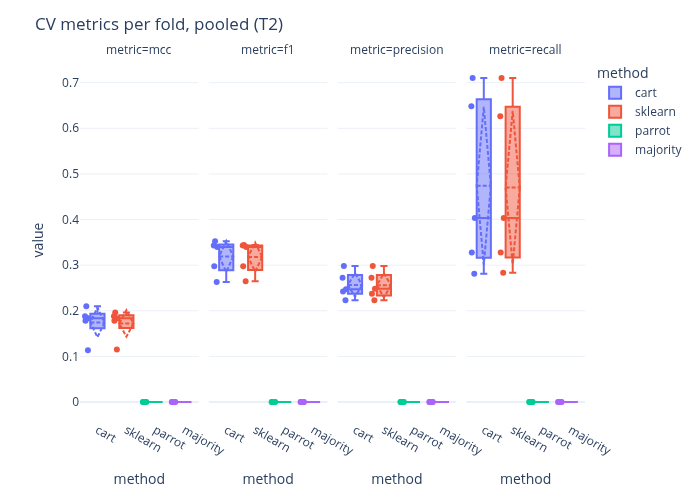

[11/08/2026 04:36:39 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_cv_folds_T2.*

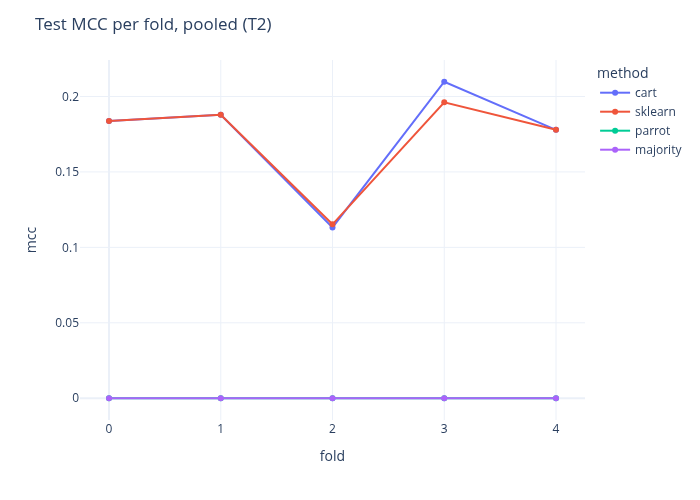

**CV results, pooled** (T1, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.330 +/- 0.049,0.422 +/- 0.082,0.583 +/- 0.082,0.351 +/- 0.119,0.795 +/- 0.028,85.800 +/- 7.011,35.078 +/- 11.917
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.778 +/- 0.018,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.330 +/- 0.038,0.467 +/- 0.037,0.503 +/- 0.031,0.436 +/- 0.042,0.780 +/- 0.016,80.753 +/- 2.026,43.647 +/- 4.185
sklearn,0.328 +/- 0.048,0.421 +/- 0.081,0.580 +/- 0.085,0.352 +/- 0.121,0.793 +/- 0.029,85.615 +/- 7.329,35.180 +/- 12.087


**CV results per source** (T1, mean +/- std over the 5 test folds)

mcc  \
source                             method                       
Homebrew__brew__9591               cart       0.033 +/- 0.097   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.305 +/- 0.101   
                                   sklearn    0.033 +/- 0.097   
astral-sh__ruff__32130301          cart       0.252 +/- 0.084   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.281 +/- 0.104   
                                   sklearn    0.252 +/- 0.084   
astral-sh__uv__82881044            cart       0.117 +/- 0.091   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.176 +/- 0.122   
                                   sklearn    0.117 +/- 0.091   
github__gh-aw__180858647           cart       0.635 +/- 0.075   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.643 +/- 0.080   
                                   sklearn    0.635 +/- 0.075   
n8n-io__n8n__33322401              cart       0.279 +/- 0.024   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.241 +/- 0.025   
                                   sklearn    0.279 +/- 0.024   
n8n-io__n8n__33323319@master       cart       0.178 +/- 0.197   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.278 +/- 0.150   
                                   sklearn    0.178 +/- 0.197   
nushell__nushell__7519865          cart      -0.045 +/- 0.073   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.125 +/- 0.223   
                                   sklearn   -0.045 +/- 0.073   
servo__servo__3876879              cart       0.168 +/- 0.113   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.200 +/- 0.099   
                                   sklearn    0.168 +/- 0.113   
sharkdp__fd__11202521              cart       0.012 +/- 0.169   
                                   majority   0.000 +/- 0.000   
                                   parrot    -0.009 +/- 0.177   
                                   sklearn    0.012 +/- 0.169   
sveltejs__svelte__14783            cart       0.142 +/- 0.270   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.163 +/- 0.283   
                                   sklearn    0.142 +/- 0.270   
tokio-rs__tokio__1972898           cart       0.147 +/- 0.280   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.082 +/- 0.232   
                                   sklearn    0.147 +/- 0.280   
windmill-labs__windmill__133951533 cart       0.682 +/- 0.186   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.625 +/- 0.139   
                                   sklearn    0.673 +/- 0.188   
windmill-labs__windmill__45664283  cart       0.590 +/- 0.266   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.641 +/- 0.268   
                                   sklearn    0.567 +/- 0.258   

                                                      recall        precision  
source                             method                                      
Homebrew__brew__9591               cart      0.077 +/- 0.145  0.097 +/- 0.136  
                                   majority  0.000 +/- 0.000  0.000 +/- 0.000  
                                   parrot    0.355 +/- 0.083  0.389 +/- 0.123  
                                   sklearn   0.077 +/- 0.145  0.097 +/- 0.136  
astral-sh__ruff__32130301          cart      0.250 +/- 0.118  0.497

**Failures per test fold and source** (T1)

fold,0,1,2,3,4
source,,,,,
Homebrew__brew__9591,6,7,6,12,37
all,799,775,784,679,675
astral-sh__ruff__32130301,60,64,31,52,83
astral-sh__uv__82881044,106,54,71,21,36
github__gh-aw__180858647,54,30,39,13,93
n8n-io__n8n__33322401,348,362,381,364,152
n8n-io__n8n__33323319@master,32,76,108,34,10
nushell__nushell__7519865,2,3,0,3,4
servo__servo__3876879,118,107,110,113,195


[11/08/2026 04:36:41 PM] INFO     Saved figure: /home/culbec/uni/ACISE/projects/2/results/figures/tree_cv_box_T1.*

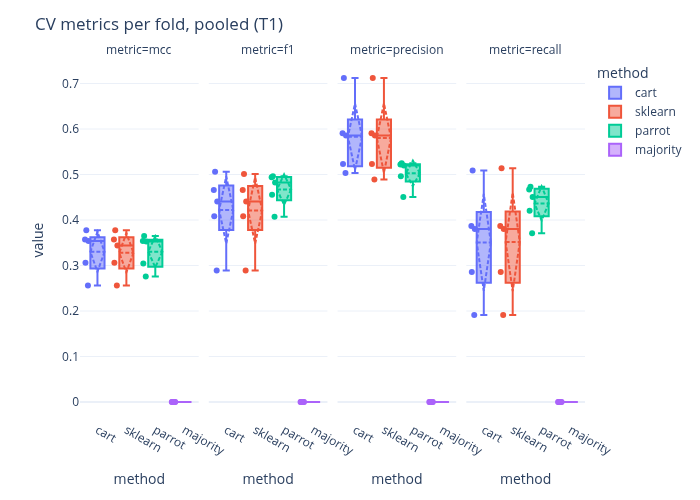

[11/08/2026 04:36:43 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_cv_folds_T1.*

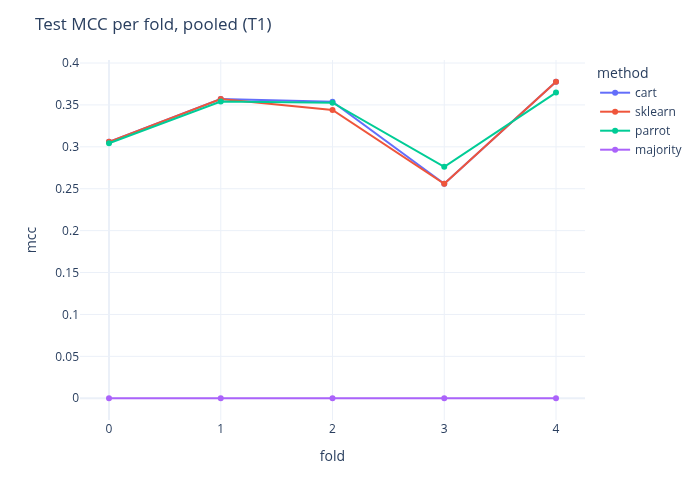

In [11]:
def mean_std(r: pd.DataFrame, metrics: list[str], by: tuple[str, ...] = ("method",)) -> pd.DataFrame:
    """'mean +/- std' over the folds (sample std, ddof=1), per `by` group."""
    g = r.groupby(list(by))[metrics]
    return g.mean().map(lambda v: f"{v:.3f}") + " +/- " + g.std().map(lambda v: f"{v:.3f}")


def pooled_rows(r: pd.DataFrame) -> pd.DataFrame:
    return r[r["source"] == "all"]


for t in TARGETS:
    r = results[t]
    display(
        Markdown(f"**CV results, pooled** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(pooled_rows(r), METRICS),
        Markdown(f"**CV results per source** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(r[r["source"] != "all"], ["mcc", "recall", "precision"], by=("source", "method")),
        Markdown(f"**Failures per test fold and source** ({t})"),
        r.query("method == 'cart'").pivot(index="source", columns="fold", values="n_fail"),
    )
    long = pooled_rows(r).melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold, pooled ({t})"), f"tree_cv_box_{t}"))
    display(plots.save(
        px.line(pooled_rows(r), x="fold", y="mcc", color="method", markers=True)
        .update_layout(title=f"Test MCC per fold, pooled ({t})"),
        f"tree_cv_folds_{t}",
    ))

## 5. Statistical tests

Paired two-sided Wilcoxon signed-rank test on the per-fold MCC, and the Vargha-Delaney A12 (P(CART fold > other fold); 0.5 = no difference). **With 5 folds the smallest reachable two-sided p is 0.0625** (`min_p`), so no comparison can reach 0.05: A12 and the per-fold table carry the result.

In [12]:
rows = []
for t in TARGETS:
    pf = st.per_fold(results[t], "mcc")
    for other in ("parrot", "majority", "sklearn"):
        w = st.paired_wilcoxon(pf["cart"], pf[other])
        rows.append(
            {
                "target": t,
                "cart vs": other,
                "mean_diff": (pf["cart"] - pf[other]).mean(),
                "p": w.p,
                "n": w.n,
                "min_p": w.min_p,
                "flag": w.flag,
                "A12": st.vargha_delaney_a12(pf["cart"], pf[other]),
            }
        )
display(
    Markdown("**CART vs. the baselines** on the pooled per-fold MCC: paired Wilcoxon and A12"),
    pd.DataFrame(rows).round(4),
)
for t in TARGETS:
    display(Markdown(f"**Test MCC per fold and method**, pooled ({t})"), st.per_fold(results[t], "mcc").round(3))

**CART vs. the baselines** on the pooled per-fold MCC: paired Wilcoxon and A12

,target,cart vs,mean_diff,p,n,min_p,flag,A12
0,T2,parrot,0.1745,0.0625,5,0.0625,NaN,1.00
1,T2,majority,0.1745,0.0625,5,0.0625,NaN,1.00
2,T2,sklearn,0.0023,1.0000,2,0.5000,zero_diffs_dropped,0.50
3,T1,parrot,-0.0003,0.6250,5,0.0625,NaN,0.56
4,T1,majority,0.3301,0.0625,5,0.0625,NaN,1.00
5,T1,sklearn,0.0020,1.0000,1,1.0000,zero_diffs_dropped,0.52


**Test MCC per fold and method**, pooled (T2)

method,cart,majority,parrot,sklearn
fold,,,,
0,0.184,0.0,0.0,0.184
1,0.188,0.0,0.0,0.188
2,0.113,0.0,0.0,0.115
3,0.210,0.0,0.0,0.196
4,0.178,0.0,0.0,0.178


**Test MCC per fold and method**, pooled (T1)

method,cart,majority,parrot,sklearn
fold,,,,
0,0.306,0.0,0.304,0.306
1,0.357,0.0,0.354,0.357
2,0.354,0.0,0.353,0.344
3,0.256,0.0,0.276,0.256
4,0.378,0.0,0.365,0.378


## 6. What the tree uses

Impurity-decrease importance of each fold's final (pruned) tree. The table gives the mean and std over the folds; the plot shows one point per fold and the dashed line is the mean. No ± std band here: importances are bounded at 0 and skewed (a feature can be large in one fold and 0 in the others), so mean − std would fall below 0.

**Impurity-decrease importance per fold** (T2, final tree of each fold), with mean and std

,0,1,2,3,4,mean,std
fail_rate_7d,0.462,0.438,0.258,0.425,0.337,0.384,0.085
author_prior_fail_rate,0.133,0.112,0.139,0.114,0.122,0.124,0.012
lineage_first_run,0.071,0.049,0.072,0.082,0.056,0.066,0.013
additions,0.045,0.039,0.096,0.091,0.047,0.064,0.028
file_fail_prob_max,0.000,0.083,0.098,0.055,0.059,0.059,0.037
days_since_workflow_change,0.049,0.047,0.092,0.048,0.053,0.058,0.019
event_pull_request,0.112,0.083,0.000,0.000,0.000,0.039,0.055
flaky_rate_7d,0.056,0.051,0.066,0.000,0.018,0.038,0.028
dir_entropy,0.043,0.024,0.023,0.033,0.055,0.036,0.013
fail_rate_3h,0.028,0.000,0.077,0.025,0.048,0.036,0.029


[11/08/2026 04:39:06 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_importance_T2.*

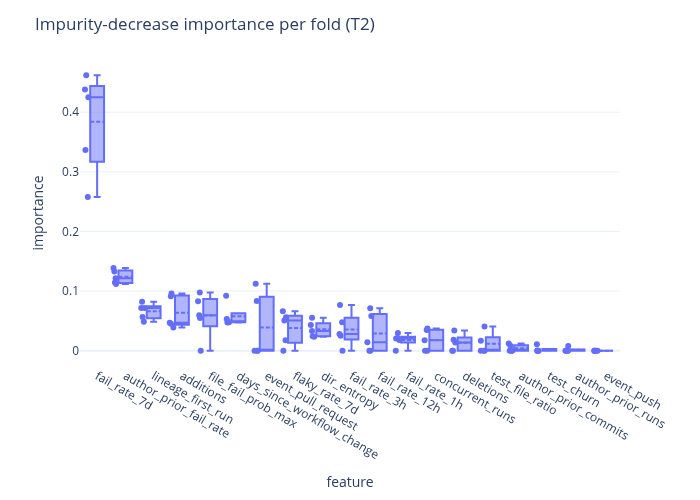

**Impurity-decrease importance per fold** (T1, final tree of each fold), with mean and std

,0,1,2,3,4,mean,std
fail_streak,0.523,0.544,0.545,0.490,0.522,0.525,0.023
fail_rate_7d,0.246,0.147,0.248,0.032,0.171,0.169,0.089
author_is_bot,0.080,0.028,0.073,0.012,0.074,0.053,0.031
file_fail_prob_max,0.045,0.052,0.048,0.052,0.051,0.050,0.003
author_prior_fail_rate,0.000,0.040,0.000,0.114,0.037,0.038,0.047
flaky_rate_7d,0.041,0.056,0.023,0.029,0.000,0.030,0.021
additions,0.014,0.040,0.000,0.035,0.008,0.019,0.017
fail_rate_3h,0.000,0.006,0.038,0.018,0.023,0.017,0.015
fail_rate_1h,0.000,0.018,0.000,0.057,0.009,0.017,0.024
deletions,0.000,0.021,0.000,0.040,0.019,0.016,0.017


[11/08/2026 04:39:09 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_importance_T1.*

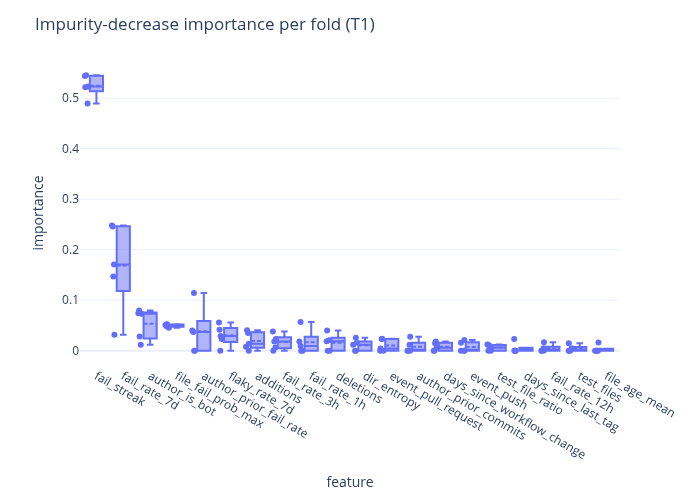

In [13]:
for t in TARGETS:
    imp = pd.DataFrame({k: p["tree"].feature_importances_ for k, p in payloads[t].items()}, index=feats[t])
    imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
    display(
        Markdown(f"**Impurity-decrease importance per fold** ({t}, final tree of each fold), with mean and std"),
        imp.assign(mean=imp.mean(axis=1), std=imp.std(axis=1)).round(3),
    )
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="fold", value_name="importance")
    display(plots.save(
        px.box(long, x="feature", y="importance", points="all", hover_data=["fold"])
        .update_traces(boxmean=True)
        .update_layout(title=f"Impurity-decrease importance per fold ({t})"),
        f"tree_importance_{t}",
    ))

The tree of the last fold (largest train set), top 3 levels. Box width = runs reaching the node, colour = P(fail).

|--- fail_rate_7d <= 0.159479
|   |--- author_prior_fail_rate <= 0.123311
|   |   |--- fail_rate_12h <= 0.0613815
|   |   |   |--- ...
|   |   |--- fail_rate_12h > 0.0613815
|   |   |   |--- ...
|   |--- author_prior_fail_rate > 0.123311
|   |   |--- days_since_workflow_change <= 22.2504
|   |   |   |--- ...
|   |   |--- days_since_workflow_change > 22.2504
|   |   |   |--- ...
|--- fail_rate_7d > 0.159479
|   |--- file_fail_prob_max <= 0.915476
|   |   |--- lineage_first_run <= 0.5
|   |   |   |--- ...
|   |   |--- lineage_first_run > 0.5
|   |   |   |--- ...
|   |--- file_fail_prob_max > 0.915476
|   |   |--- dir_entropy <= 2.55361
|   |   |   |--- ...
|   |   |--- dir_entropy > 2.55361
|   |   |   |--- leaf: P(fail) = 0.84 from 409 runs


[11/08/2026 04:39:24 PM] INFO     Saved figure: /home/culbec/uni/ACISE/projects/2/results/figures/tree_icicle_T2.*

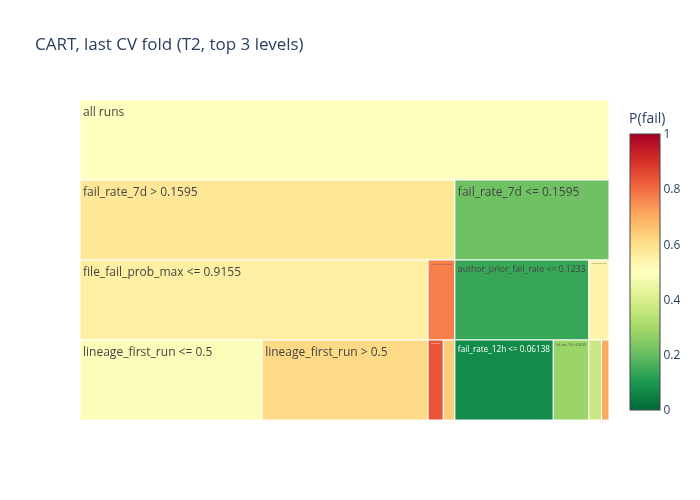

In [14]:
last = payloads["T2"][max(payloads["T2"])]["tree"]
print(last.export_text(max_depth=3))
plots.save(
    plots.tree_icicle(last.tree_, last.feature_names_, max_depth=3).update_layout(title="CART, last CV fold (T2, top 3 levels)"),
    "tree_icicle_T2",
)

## 7. Errors and the cost trade-off

Confusion matrix of CART, summed over the 5 test folds: pooled, then per source.

[11/08/2026 04:40:20 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_confusion_T2.*

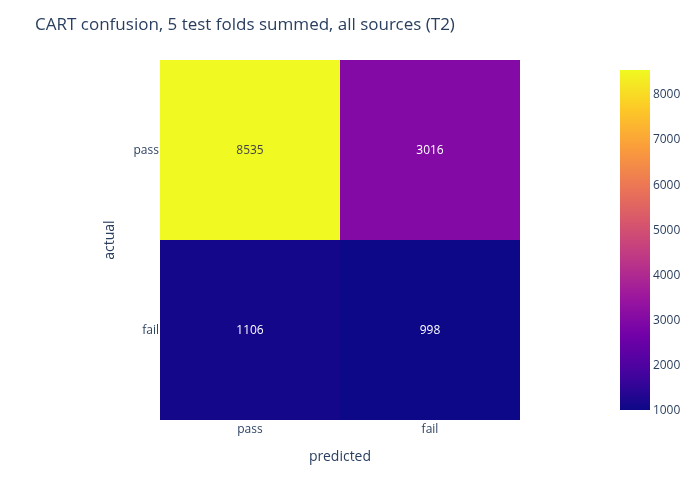

**CART confusion per source** (T2, summed over the 5 test folds)

,tn,fp,fn,tp
source,,,,
Homebrew__brew__9591,540,11,42,4
astral-sh__ruff__32130301,1013,224,108,76
astral-sh__uv__82881044,382,303,109,80
github__gh-aw__180858647,98,14,28,4
n8n-io__n8n__33322401,2505,1551,455,530
n8n-io__n8n__33323319@master,321,148,66,32
nushell__nushell__7519865,243,2,12,0
servo__servo__3876879,815,420,191,205
sharkdp__fd__11202521,59,7,7,1


[11/08/2026 04:40:21 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_confusion_T1.*

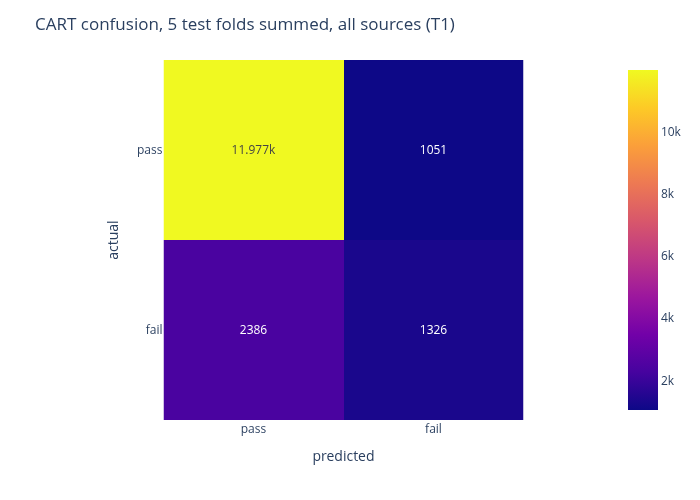

**CART confusion per source** (T1, summed over the 5 test folds)

,tn,fp,fn,tp
source,,,,
Homebrew__brew__9591,550,17,64,4
astral-sh__ruff__32130301,1300,72,222,68
astral-sh__uv__82881044,698,107,212,76
github__gh-aw__180858647,101,30,31,198
n8n-io__n8n__33322401,4304,499,1064,543
n8n-io__n8n__33323319@master,475,92,111,149
nushell__nushell__7519865,239,7,12,0
servo__servo__3876879,1347,174,485,158
sharkdp__fd__11202521,63,5,8,2


In [15]:
def pooled(t: str, method: str, source: str = "all") -> pd.Series:
    r = results[t]
    return r[(r["method"] == method) & (r["source"] == source)][["tn", "fp", "fn", "tp"]].sum()


for t in TARGETS:
    c = pooled(t, "cart")
    display(plots.save(
        plots.confusion(np.array([[c.tn, c.fp], [c.fn, c.tp]]))
        .update_layout(title=f"CART confusion, 5 test folds summed, all sources ({t})"),
        f"tree_confusion_{t}",
    ))
    per_source = results[t].query("method == 'cart' and source != 'all'").groupby("source")[["tn", "fp", "fn", "tp"]].sum()
    display(Markdown(f"**CART confusion per source** ({t}, summed over the 5 test folds)"), per_source)

**Trade-off.** Each fold's tree scores its test fold; the probabilities are pooled and one threshold is swept over all of them. A higher threshold skips more builds (`% builds saved`) and catches fewer failures. The star is CART with its tuned per-fold thresholds; the diamond is Parrot. The dotted line is a random guess that flags a share q of the builds and so catches a share q of the failures (caught = 100 - saved): the distance above it is what the model adds.

**Pooled, not averaged.** Every point here counts all test runs together, so folds with more failures weigh more, and it differs from the fold means above. A single global threshold read off this curve uses the test labels, so it is a diagnosis of the threshold choice, not a result.

[11/08/2026 04:40:57 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_tradeoff_T2.*

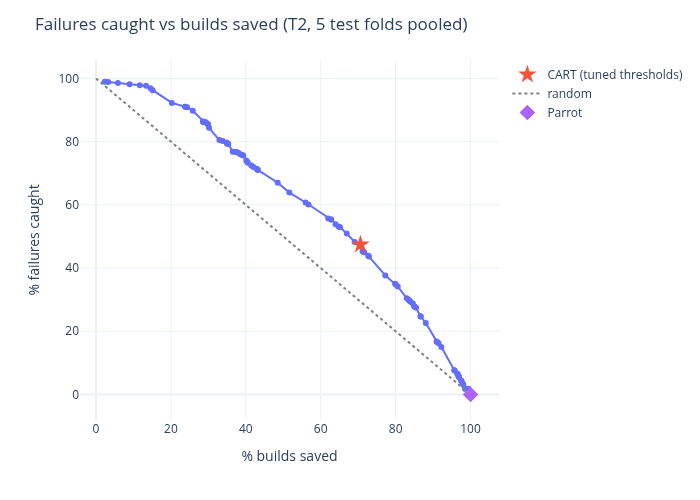

[11/08/2026 04:40:59 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/tree_tradeoff_T1.*

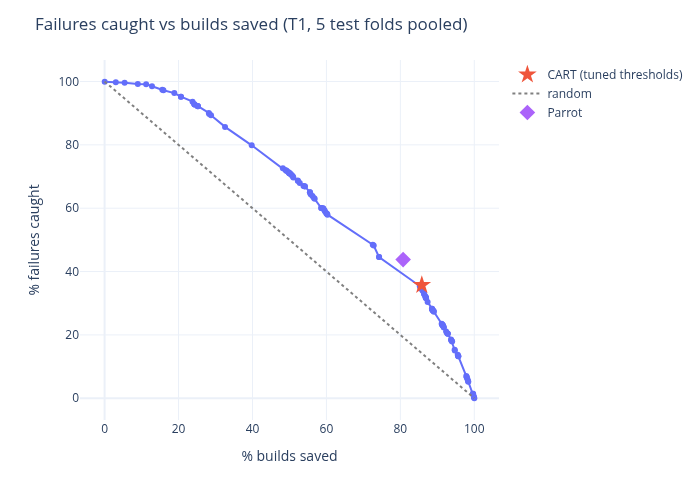

In [16]:
def point(c: pd.Series) -> tuple[float, float]:
    return 100 * (c.tn + c.fn) / c.sum(), 100 * c.tp / (c.tp + c.fn)


for t in TARGETS:
    proba = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    curve = pd.DataFrame(
        [
            {"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)}
            for th in np.unique(np.r_[0.0, proba])
        ]
    )
    fig = plots.tradeoff(curve, point(pooled(t, "cart")), "CART (tuned thresholds)")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved ({t}, 5 test folds pooled)"), f"tree_tradeoff_{t}"))

## 8. E1 and E3

_Added with the per-source experiments: CART per source on its own feature list (E1), and leave one repository out (E3)._

## 9. Random forest (bagging over CART)

A single CART is a weak learner. A random forest (Breiman, 2001; `tree/forest.py`) averages 100 of our own CART trees. Each tree is fitted on a bootstrap sample of the fit rows and draws sqrt(p) columns at every node, so the trees differ and part of their errors cancel. P(fail) is the mean of the trees' leaf shares.

**Protocol.** Same folds, features and validation tail as CART, scored pooled and per source. The trees are not pruned. The grid (`max_depth` in {8, None} x `min_samples_leaf` in {5, 20} x class weight = 8 points) and the decision threshold are chosen on validation MCC; each test fold is read once. The seed is fixed (`random_state=0`), so each fold is run once, as for CART.

**What it costs.** A forest has no single readable path, so it is not the model we explain. It shows how much accuracy the single tree gives up for its explanation.

In [17]:
rf_payloads = {}
for t in TARGETS:
    print(f"Target: {t}")
    rf, rf_payloads[t] = run_cv(data[t], feats[t], forest.fit_predict, "forest")
    # drop an earlier forest run first, so the cell can be re-run
    results[t] = pd.concat([results[t].query("method != 'forest'"), rf], ignore_index=True)

Output()

[11/08/2026 04:41:08 PM] INFO     forest fold 1/5: fit 5467, val 1366, test 2731 (471 failures)

Target: T2


[11/08/2026 04:41:26 PM] INFO     forest fold 2/5: fit 7652, val 1912, test 2731 (421 failures)

[11/08/2026 04:41:51 PM] INFO     forest fold 3/5: fit 9836, val 2459, test 2731 (434 failures)

/home/culbec/uni/ACISE/projects/2/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:614: 
UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape,
use the 'labels' parameter to pass all known labels.
  warnings.warn(

... (6 outputs left out)

[11/08/2026 04:44:55 PM] INFO     forest fold 3/5: fit 12056, val 3014, test 3348 (784 failures)

/home/culbec/uni/ACISE/projects/2/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:614: 
UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape,
use the 'labels' parameter to pass all known labels.
  warnings.warn(

[11/08/2026 04:45:39 PM] INFO     forest fold 4/5: fit 14735, val 3683, test 3348 (679 failures)

[11/08/2026 04:46:34 PM] INFO     forest fold 5/5: fit 17413, val 4353, test 3348 (675 failures)

Choice per fold, with the validation MCC it was chosen on, the test MCC, and CART's test MCC on the same fold.

In [18]:
rf_mcc = {t: results[t].query("method == 'forest' and source == 'all'").set_index("fold")["mcc"] for t in TARGETS}
display(
    Markdown("**Forest choice per fold**: grid parameters, threshold, mean tree depth, the validation MCC it was "
             "chosen on, the pooled test MCC, and CART's pooled test MCC on the same fold"),
    pd.DataFrame(
        [
            {
                "target": t,
                "fold": k,
                **p["choice"].params,
                "threshold": p["choice"].threshold,
                "mean_depth": np.mean([tr.depth_ for tr in p["forest"].estimators_]),
                "val_mcc": p["choice"].val_mcc,
                "test_mcc": rf_mcc[t][k],
                "cart_test_mcc": test_mcc[t][k],
            }
            for t in TARGETS
            for k, p in rf_payloads[t].items()
        ]
    ).round(4),
)

**Forest choice per fold**: grid parameters, threshold, mean tree depth, the validation MCC it was chosen on, the pooled test MCC, and CART's pooled test MCC on the same fold

,target,fold,max_depth,min_samples_leaf,class_weight,threshold,mean_depth,val_mcc,test_mcc,cart_test_mcc
0,T2,0,NaN,20,NaN,0.1888,15.24,0.3497,0.2283,0.1837
1,T2,1,8.0,20,NaN,0.1660,8.00,0.2505,0.2161,0.1878
2,T2,2,8.0,5,balanced,0.6514,8.00,0.2769,0.1574,0.1132
3,T2,3,NaN,20,balanced,0.4620,18.96,0.2698,0.2389,0.2098
4,T2,4,NaN,20,NaN,0.1885,19.74,0.2260,0.2420,0.1779
5,T1,0,8.0,5,balanced,0.6213,8.00,0.4833,0.3106,0.3059
6,T1,1,8.0,5,balanced,0.5096,8.00,0.3137,0.3470,0.3571
7,T1,2,NaN,20,NaN,0.3146,20.72,0.4207,0.3616,0.3539
8,T1,3,8.0,20,NaN,0.3723,8.00,0.4285,0.3028,0.2560
9,T1,4,8.0,20,NaN,0.3780,8.00,0.3839,0.3963,0.3777


Mean +/- std over the 5 test folds, pooled and per source, next to CART and the baselines (same tables and plots as section 4).

**CV results, pooled, forest vs. CART and the baselines** (T2, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.174 +/- 0.036,0.319 +/- 0.038,0.257 +/- 0.029,0.474 +/- 0.193,0.698 +/- 0.089,70.604 +/- 14.548,47.413 +/- 19.342
forest,0.217 +/- 0.035,0.331 +/- 0.090,0.305 +/- 0.083,0.507 +/- 0.231,0.714 +/- 0.082,71.241 +/- 15.361,50.731 +/- 23.076
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.846 +/- 0.014,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.846 +/- 0.014,100.000 +/- 0.000,0.000 +/- 0.000


**CV results per source, forest vs. CART and the baselines** (T2, mean +/- std over the 5 test folds)

mcc  \
source                             method                       
Homebrew__brew__9591               cart       0.136 +/- 0.190   
                                   forest     0.173 +/- 0.184   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
astral-sh__ruff__32130301          cart       0.205 +/- 0.116   
                                   forest     0.197 +/- 0.151   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
astral-sh__uv__82881044            cart       0.058 +/- 0.087   
                                   forest     0.184 +/- 0.104   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
github__gh-aw__180858647           cart       0.060 +/- 0.184   
                                   forest     0.026 +/- 0.194   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
n8n-io__n8n__33322401              cart       0.143 +/- 0.038   
                                   forest     0.144 +/- 0.037   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
n8n-io__n8n__33323319@master       cart       0.047 +/- 0.091   
                                   forest     0.084 +/- 0.095   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
nushell__nushell__7519865          cart      -0.017 +/- 0.025   
                                   forest    -0.035 +/- 0.035   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
servo__servo__3876879              cart       0.156 +/- 0.047   
                                   forest     0.145 +/- 0.055   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
sharkdp__fd__11202521              cart       0.012 +/- 0.243   
                                   forest     0.205 +/- 0.484   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
sveltejs__svelte__14783            cart       0.166 +/- 0.314   
                                   forest     0.015 +/- 0.062   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
tokio-rs__tokio__1972898           cart       0.114 +/- 0.268   
                                   forest     0.254 +/- 0.305   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
windmill-labs__windmill__133951533 cart       0.351 +/- 0.240   
                                   forest     0.560 +/- 0.184   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   
windmill-labs__windmill__45664283  cart       0.104 +/- 0.165   
                                   forest     0.166 +/- 0.163   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.000 +/- 0.000   

                                                      recall        precision  
source                             method                                      
Homebrew__brew__9591               cart      0.138 +/- 0.179  0.213 +/- 0.229  
                                   forest    0.161 +/- 0.170  0.330 +/- 0.412  
                                   majority  0.000 +/- 0.000  0.000 +/- 0.000  
                                   parrot    0.000 +/- 0.000  0.000 +/- 0.000  
astral-sh__ruff__32130301          cart      0.437 +/- 0.258  0.266

[11/08/2026 04:47:41 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_cv_box_T2.*

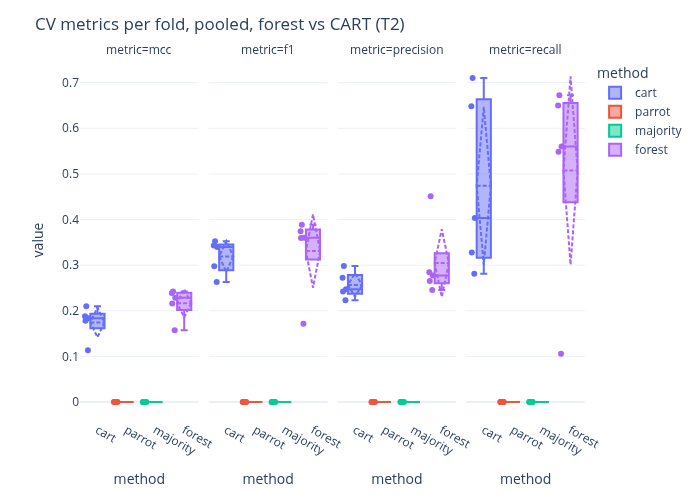

[11/08/2026 04:47:43 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_cv_folds_T2.*

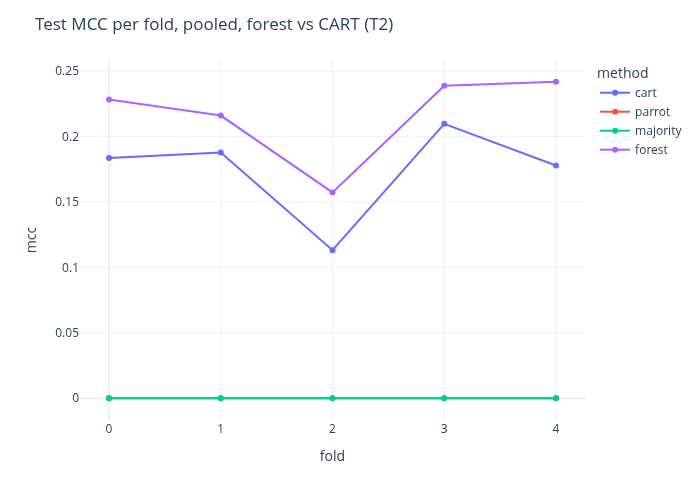

**CV results, pooled, forest vs. CART and the baselines** (T1, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.330 +/- 0.049,0.422 +/- 0.082,0.583 +/- 0.082,0.351 +/- 0.119,0.795 +/- 0.028,85.800 +/- 7.011,35.078 +/- 11.917
forest,0.344 +/- 0.038,0.457 +/- 0.064,0.548 +/- 0.070,0.417 +/- 0.135,0.787 +/- 0.034,82.168 +/- 8.694,41.711 +/- 13.465
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.778 +/- 0.018,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.330 +/- 0.038,0.467 +/- 0.037,0.503 +/- 0.031,0.436 +/- 0.042,0.780 +/- 0.016,80.753 +/- 2.026,43.647 +/- 4.185


**CV results per source, forest vs. CART and the baselines** (T1, mean +/- std over the 5 test folds)

mcc  \
source                             method                       
Homebrew__brew__9591               cart       0.033 +/- 0.097   
                                   forest     0.178 +/- 0.213   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.305 +/- 0.101   
astral-sh__ruff__32130301          cart       0.252 +/- 0.084   
                                   forest     0.259 +/- 0.072   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.281 +/- 0.104   
astral-sh__uv__82881044            cart       0.117 +/- 0.091   
                                   forest     0.165 +/- 0.106   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.176 +/- 0.122   
github__gh-aw__180858647           cart       0.635 +/- 0.075   
                                   forest     0.614 +/- 0.083   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.643 +/- 0.080   
n8n-io__n8n__33322401              cart       0.279 +/- 0.024   
                                   forest     0.298 +/- 0.028   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.241 +/- 0.025   
n8n-io__n8n__33323319@master       cart       0.178 +/- 0.197   
                                   forest     0.303 +/- 0.169   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.278 +/- 0.150   
nushell__nushell__7519865          cart      -0.045 +/- 0.073   
                                   forest    -0.025 +/- 0.035   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.125 +/- 0.223   
servo__servo__3876879              cart       0.168 +/- 0.113   
                                   forest     0.166 +/- 0.062   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.200 +/- 0.099   
sharkdp__fd__11202521              cart       0.012 +/- 0.169   
                                   forest    -0.009 +/- 0.190   
                                   majority   0.000 +/- 0.000   
                                   parrot    -0.009 +/- 0.177   
sveltejs__svelte__14783            cart       0.142 +/- 0.270   
                                   forest     0.143 +/- 0.190   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.163 +/- 0.283   
tokio-rs__tokio__1972898           cart       0.147 +/- 0.280   
                                   forest     0.146 +/- 0.258   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.082 +/- 0.232   
windmill-labs__windmill__133951533 cart       0.682 +/- 0.186   
                                   forest     0.665 +/- 0.161   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.625 +/- 0.139   
windmill-labs__windmill__45664283  cart       0.590 +/- 0.266   
                                   forest     0.628 +/- 0.249   
                                   majority   0.000 +/- 0.000   
                                   parrot     0.641 +/- 0.268   

                                                      recall        precision  
source                             method                                      
Homebrew__brew__9591               cart      0.077 +/- 0.145  0.097 +/- 0.136  
                                   forest    0.182 +/- 0.190  0.284 +/- 0.279  
                                   majority  0.000 +/- 0.000  0.000 +/- 0.000  
                                   parrot    0.355 +/- 0.083  0.389 +/- 0.123  
astral-sh__ruff__32130301          cart      0.250 +/- 0.118  0.497

[11/08/2026 04:47:45 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_cv_box_T1.*

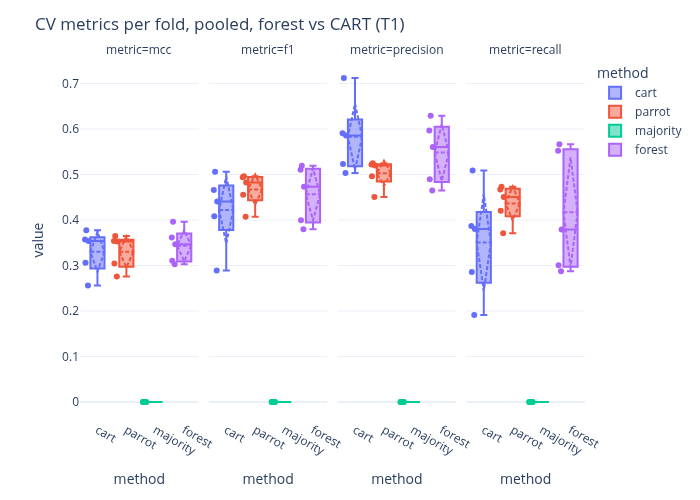

[11/08/2026 04:47:47 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_cv_folds_T1.*

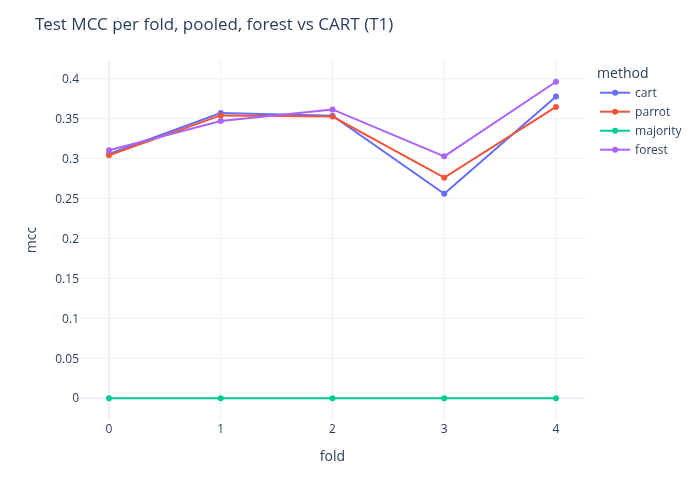

In [19]:
COMPARE = ["forest", "cart", "parrot", "majority"]
for t in TARGETS:
    r = results[t][results[t].method.isin(COMPARE)]
    display(
        Markdown(f"**CV results, pooled, forest vs. CART and the baselines** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(pooled_rows(r), METRICS),
        Markdown(f"**CV results per source, forest vs. CART and the baselines** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(r[r["source"] != "all"], ["mcc", "recall", "precision"], by=("source", "method")),
    )
    long = pooled_rows(r).melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold, pooled, forest vs CART ({t})"), f"forest_cv_box_{t}"))
    display(plots.save(
        px.line(pooled_rows(r), x="fold", y="mcc", color="method", markers=True)
        .update_layout(title=f"Test MCC per fold, pooled, forest vs CART ({t})"),
        f"forest_cv_folds_{t}",
    ))

**Statistical tests.** As in section 5: paired Wilcoxon on the per-fold MCC (smallest reachable p with 5 folds: 0.0625) and A12 = P(forest fold > other fold).

In [20]:
rows = []
for t in TARGETS:
    pf = st.per_fold(results[t], "mcc")
    for other in ("cart", "parrot", "majority"):
        w = st.paired_wilcoxon(pf["forest"], pf[other])
        rows.append(
            {
                "target": t,
                "forest vs": other,
                "mean_diff": (pf["forest"] - pf[other]).mean(),
                "p": w.p,
                "n": w.n,
                "min_p": w.min_p,
                "flag": w.flag,
                "A12": st.vargha_delaney_a12(pf["forest"], pf[other]),
            }
        )
display(
    Markdown("**Forest vs. CART and the baselines** on the pooled per-fold MCC: paired Wilcoxon and A12"),
    pd.DataFrame(rows).round(4),
)

**Forest vs. CART and the baselines** on the pooled per-fold MCC: paired Wilcoxon and A12

,target,forest vs,mean_diff,p,n,min_p,flag,A12
0,T2,cart,0.0421,0.0625,5,0.0625,None,0.84
1,T2,parrot,0.2165,0.0625,5,0.0625,None,1.00
2,T2,majority,0.2165,0.0625,5,0.0625,None,1.00
3,T1,cart,0.0136,0.3125,5,0.0625,None,0.56
4,T1,parrot,0.0133,0.1875,5,0.0625,None,0.56
5,T1,majority,0.3437,0.0625,5,0.0625,None,1.00


**What the forest uses.** Impurity-decrease importance averaged over the 100 trees, then over the 5 folds, next to CART's mean from section 6. The column draw forces the forest to split on features the single tree never reaches, so its importances are spread more evenly.

**Mean impurity-decrease importance**, forest vs. CART (T2, mean over the 5 folds)

,forest,cart
author_prior_fail_rate,0.098,0.124
fail_rate_7d,0.097,0.384
file_fail_prob_max,0.090,0.059
fail_rate_12h,0.073,0.029
days_since_workflow_change,0.064,0.058
fail_rate_3h,0.062,0.036
additions,0.060,0.064
fail_rate_1h,0.057,0.018
deletions,0.051,0.013
flaky_rate_7d,0.050,0.038


[11/08/2026 04:47:49 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_importance_T2.*

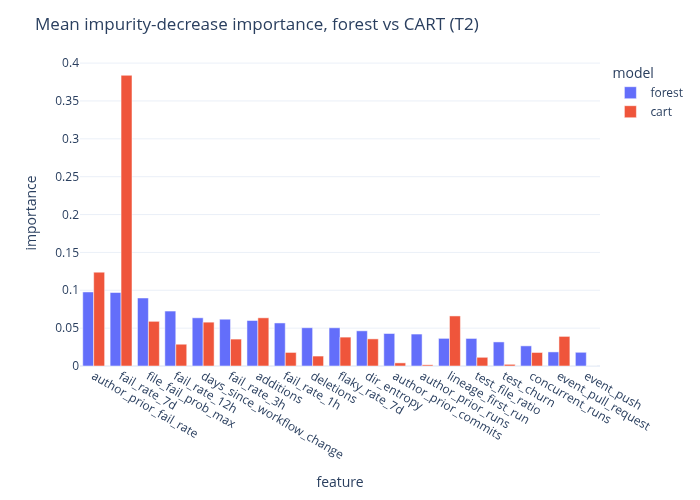

**Mean impurity-decrease importance**, forest vs. CART (T1, mean over the 5 folds)

,forest,cart
fail_streak,0.189,0.525
author_prior_fail_rate,0.101,0.038
file_fail_prob_max,0.100,0.050
fail_rate_1h,0.078,0.017
fail_rate_7d,0.071,0.169
fail_rate_12h,0.064,0.004
fail_rate_3h,0.058,0.017
additions,0.047,0.019
days_since_workflow_change,0.040,0.008
deletions,0.038,0.016


[11/08/2026 04:47:50 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_importance_T1.*

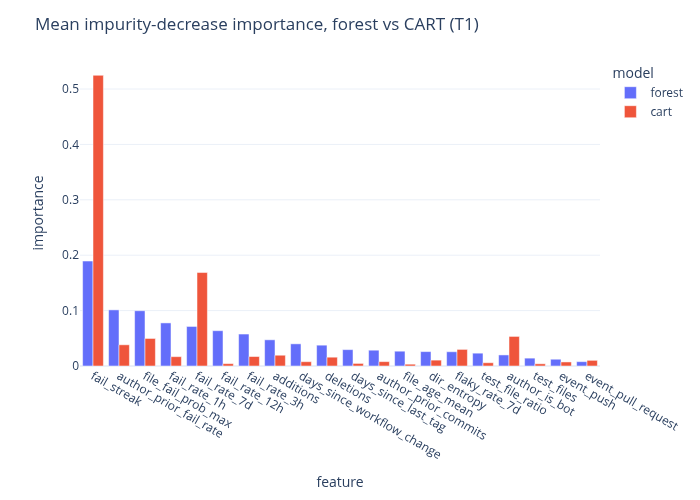

In [21]:
for t in TARGETS:
    imp = pd.DataFrame(
        {
            "forest": np.mean([p["forest"].feature_importances_ for p in rf_payloads[t].values()], axis=0),
            "cart": np.mean([p["tree"].feature_importances_ for p in payloads[t].values()], axis=0),
        },
        index=feats[t],
    ).sort_values("forest", ascending=False)
    display(Markdown(f"**Mean impurity-decrease importance**, forest vs. CART ({t}, mean over the 5 folds)"), imp.round(3))
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")
    display(plots.save(
        px.bar(long, x="feature", y="importance", color="model", barmode="group")
        .update_layout(title=f"Mean impurity-decrease importance, forest vs CART ({t})"),
        f"forest_importance_{t}",
    ))

**Trade-off.** The pooled curve of section 7, for the forest and CART on the same axes. The forest gives almost every run its own P(fail), so its curve is drawn at 201 quantile thresholds. The star is the forest with its tuned per-fold thresholds. As in section 7, the curve uses the test labels and is a diagnosis of the ranking, not a result.

[11/08/2026 04:47:52 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_tradeoff_T2.*

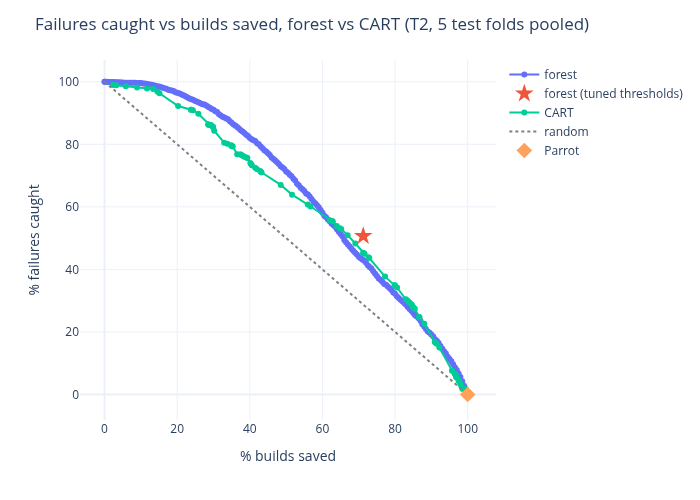

[11/08/2026 04:47:55 PM] INFO     Saved figure:                                                                    
                                  /home/culbec/uni/ACISE/projects/2/results/figures/forest_tradeoff_T1.*

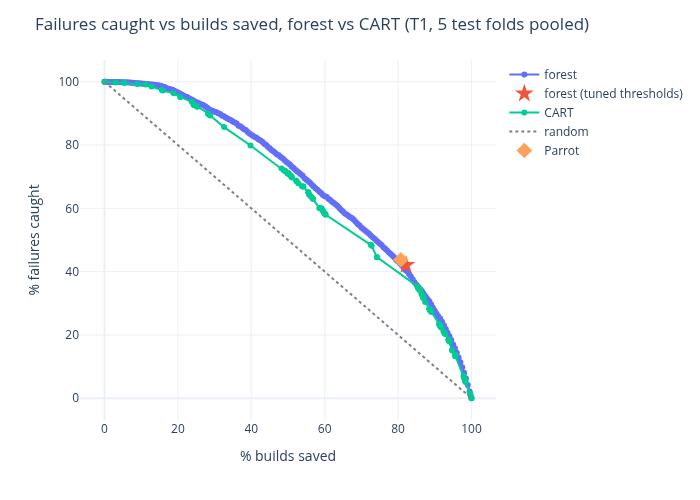

In [22]:
def sweep(proba: np.ndarray, y: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame(
        [{"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)} for th in thresholds]
    )


for t in TARGETS:
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    p_rf = np.concatenate([rf_payloads[t][k]["forest"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    p_cart = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    fig = plots.tradeoff(
        sweep(p_rf, y, np.unique(np.r_[0.0, np.quantile(p_rf, np.linspace(0, 1, 201))])),
        point(pooled(t, "forest")),
        "forest (tuned thresholds)",
    )
    fig.data[0].update(name="forest", showlegend=True)
    c = sweep(p_cart, y, np.unique(np.r_[0.0, p_cart]))
    fig.add_scatter(x=c.saved, y=c.caught, mode="lines+markers", name="CART")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved, forest vs CART ({t}, 5 test folds pooled)"), f"forest_tradeoff_{t}"))

## Observations

_To be written after the run on the pooled data._